# Manufacturing Defect Analysis — Submission Notebook

**Read before you start:**
- Do not rename, delete, reorder, or merge the section headers below (the `## SECTION` lines). The grading system locates your work by these headers.
- For sections with code (Sections 1-3), write and run your code first, then answer the questions in the markdown cell that follows it, using your actual output. For sections without code (Sections 4 onward), just answer in the markdown cell provided. Use the cells as provided — add more cells *within* a section if you need to, but keep the section headers intact and in order.
- Make sure every cell has been run and its output is visible before you submit, and do not delete or edit code cells after running them.
- Chart images will not be read by the grading system — anything the grader needs to know about a chart must also be stated in words in the markdown cell for that section.
- Wherever this template asks you to **state** something (e.g. your chart type, your test name), write it as a plain sentence. Do not rely on the grader inferring it from your code or your chart.


## SECTION 1: DATA PREPARATION

Clean the dataset in the code cell below. Then, in the answer cell that follows, describe the cleaning steps you applied and why. A short list is fine.

**Step 1.1 – Load the data and count missing values.**
Purpose: import the libraries, read `G19_data.csv`, and see how many values are missing in each column before changing anything.

- `pandas` handles tables of data (DataFrames), `numpy` provides numerical helpers, `matplotlib.pyplot` draws the charts and `scipy.stats` runs the statistical tests.
- `G19_data.csv` must be in the same folder as this notebook.
- `isna().sum()` counts the missing values in each column.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

raw_data = pd.read_csv("G19_data.csv")

print("Rows and columns:", raw_data.shape)
print()
print("Missing values in each column:")
print(raw_data.isna().sum())

Rows and columns: (1000, 21)

Missing values in each column:
Cutting_Speed            10
Feed_Rate                10
Spindle_Speed            10
Tool_Wear                10
Coolant_Temperature      10
Vibration_Amplitude      10
Workpiece_Hardness       10
Ambient_Temperature      10
Humidity                 10
Tool_Angle               10
Clamping_Pressure        10
Machine_Load             59
Material_Thickness       10
Surface_Roughness        10
Power_Consumption        10
Conveyor_Speed           10
Alignment_Error          10
Tool_Change_Frequency    10
Lubricant_Flow_Rate      10
Cycle_Time               10
defect                    0
dtype: int64


**Step 1.2 – Remove completely blank rows and check for duplicates.**
Purpose: find rows where all 20 process parameters are missing, check whether the duplicate rows are real repeated units or just blank rows, then remove the blank rows.

- The 20 process parameters are every column except the `defect` label.
- `isna().all(axis=1)` is True for a row only when all 20 parameters in that row are missing (only the defect label is filled).
- Duplicate rows are counted before and after removing the blank rows, to see whether any real units are repeated.
- `raw_data[~all_blank]` keeps only the rows that are not blank (`~` means "not").
- The last part lists the columns that still have missing values.

In [2]:
parameter_columns = [col for col in raw_data.columns if col != "defect"]

all_blank = raw_data[parameter_columns].isna().all(axis=1)
print("Rows with all 20 parameters blank:", all_blank.sum())
print("Their row index numbers:", raw_data.index[all_blank].tolist())
print()

print("Duplicate rows before removing blank rows:", raw_data.duplicated().sum())

clean_data = raw_data[~all_blank].copy()

print("Duplicate rows after removing blank rows: ", clean_data.duplicated().sum())
print()

print("Rows remaining:", len(clean_data))
print("Units per group (1 = Defect, 0 = No Defect):")
print(clean_data["defect"].value_counts())
print()

remaining_missing = clean_data.isna().sum()
print("Missing values still present:")
print(remaining_missing[remaining_missing > 0])

Rows with all 20 parameters blank: 10
Their row index numbers: [128, 189, 267, 329, 346, 417, 658, 795, 856, 876]

Duplicate rows before removing blank rows: 8
Duplicate rows after removing blank rows:  0

Rows remaining: 990
Units per group (1 = Defect, 0 = No Defect):
defect
0    654
1    336
Name: count, dtype: int64

Missing values still present:
Machine_Load    49
dtype: int64


**Step 1.3 – Check for impossible values and redundant columns.**
Purpose: look for negative values (physically impossible for these parameters), count exact zeros, and check whether any column simply repeats another.

- A negative value would be impossible for every parameter in this dataset.
- Exact zeros can be plausible (for example, a brand-new tool has zero wear) or suspicious, so they are counted and checked.
- `np.polyfit(x, y, 1)` fits a straight line y = slope × x + intercept. Together with the correlation r, it shows whether Lubricant_Flow_Rate is just a rescaled copy of Humidity.

In [3]:
negative_counts = (clean_data[parameter_columns] < 0).sum()
print("Total negative values in all parameters:", negative_counts.sum())
print()

zero_counts = (clean_data[parameter_columns] == 0).sum()
print("Columns containing zeros:")
print(zero_counts[zero_counts > 0])
print("Row index with Feed_Rate = 0:", clean_data.index[clean_data["Feed_Rate"] == 0].tolist())
print()

r_lube_humidity = clean_data["Lubricant_Flow_Rate"].corr(clean_data["Humidity"])
slope, intercept = np.polyfit(clean_data["Humidity"], clean_data["Lubricant_Flow_Rate"], 1)
print(f"Correlation between Lubricant_Flow_Rate and Humidity: r = {r_lube_humidity:.5f}")
print(f"Best-fit line: Lubricant_Flow_Rate = {slope:.2f} x Humidity {intercept:+.2f}")

Total negative values in all parameters: 0

Columns containing zeros:
Feed_Rate          1
Tool_Wear          8
Alignment_Error    2
dtype: int64
Row index with Feed_Rate = 0: [942]

Correlation between Lubricant_Flow_Rate and Humidity: r = 0.99999
Best-fit line: Lubricant_Flow_Rate = 1.50 x Humidity -35.00


**Step 1.4 – Check my chosen variable, Clamping_Pressure, for outliers (IQR method).**
Purpose: values below Q1 − 1.5 × IQR or above Q3 + 1.5 × IQR are flagged as outliers, then each is checked to decide whether it is an error or a genuine reading.

- Q1 is the 25th percentile, Q3 is the 75th percentile, and IQR = Q3 − Q1 is the spread of the middle 50% of the values.
- Decision: all outliers are kept (reasons in the answer below). The cleaned data, `clean_data`, is used for the rest of the notebook.

In [4]:
pressure = clean_data["Clamping_Pressure"]

q1 = pressure.quantile(0.25)
q3 = pressure.quantile(0.75)
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

print(f"Q1 = {q1:.2f} bar, Q3 = {q3:.2f} bar, IQR = {iqr:.2f} bar")
print(f"Lower fence = {q1:.2f} - 1.5 x {iqr:.2f} = {lower_fence:.2f} bar")
print(f"Upper fence = {q3:.2f} + 1.5 x {iqr:.2f} = {upper_fence:.2f} bar")
print(f"Recorded range of Clamping_Pressure: {pressure.min():.1f} to {pressure.max():.1f} bar")
print()

outliers = clean_data[(pressure < lower_fence) | (pressure > upper_fence)]
print("Number of outliers:", len(outliers))
print(outliers[["Clamping_Pressure", "defect"]].sort_values("Clamping_Pressure"))
print()

print("Final cleaned dataset:", clean_data.shape[0], "rows")

Q1 = 89.00 bar, Q3 = 109.65 bar, IQR = 20.65 bar
Lower fence = 89.00 - 1.5 x 20.65 = 58.02 bar
Upper fence = 109.65 + 1.5 x 20.65 = 140.62 bar
Recorded range of Clamping_Pressure: 50.0 to 150.0 bar

Number of outliers: 9
     Clamping_Pressure  defect
927               50.0       0
488               53.4       0
716               53.6       0
348              141.3       0
641              142.3       1
325              146.3       1
143              147.1       1
63               148.8       0
698              150.0       1

Final cleaned dataset: 990 rows


**Your answer:**

I started with 1,000 rows and 21 columns (20 process parameters plus `defect`). The cleaning steps were:

1. **Removed 10 completely blank rows.** Row indices 128, 189, 267, 329, 346, 417, 658, 795, 856 and 876 had all 20 parameters missing; only the `defect` label was filled. These rows contain no measurements, and filling in 20 values per row would mean inventing data, so I removed them.
2. **Checked for duplicates before and after.** `duplicated()` found 8 duplicate rows in the raw file, but all 8 were blank rows (blank rows with the same defect label look identical). After removing the blank rows there were 0 duplicates, so no real units were removed as duplicates.
3. **Kept the 49 rows that are missing only Machine_Load, without imputing.** These rows are complete for Clamping_Pressure, my chosen variable, so dropping them would waste valid data. Machine_Load is only used in one correlation check in Section 3, where pandas simply leaves out the missing pairs.
4. **Checked for impossible values.** There were no negative values. Zeros appeared in Feed_Rate (1 row, index 942), Tool_Wear (8 rows) and Alignment_Error (2 rows). Zero tool wear (a new tool) and zero alignment error (perfect alignment) are plausible. A feed rate of zero is unusual for machining, so I flagged row 942, but I kept it because its Clamping_Pressure value is valid and Feed_Rate is not part of my analysis.
5. **Flagged a redundant column.** Lubricant_Flow_Rate = 1.50 × Humidity − 35.00 (r = 0.99999), so it carries no extra information. It does not affect my analysis, but anyone modelling with all columns should drop one of the two.
6. **Checked Clamping_Pressure for outliers with the IQR method.** Q1 = 89.00 bar, Q3 = 109.65 bar and IQR = 20.65 bar give fences of 58.02 and 140.62 bar. Nine values fall outside them (50.0, 53.4, 53.6, 141.3, 142.3, 146.3, 147.1, 148.8 and 150.0 bar). All nine are within the 50–150 bar range covered by the data and look like genuine low and high settings, not recording errors, so I kept them. My main test in Section 3 (Mann-Whitney U) uses ranks, so a few extreme values cannot dominate the result.

**Final cleaned dataset:** 990 units – 336 Defect and 654 No Defect.

## SECTION 2: VISUAL ANALYSIS

Choose one of the twenty process parameters to compare between Defect and No Defect groups, and produce your chart and descriptive statistics in the code cell below. Then, in the answer cell that follows, state your variable and chart type explicitly, justify your chart choice, and report the pattern you observe.

**Step 2.1 – Descriptive statistics of Clamping_Pressure for each group.**
Purpose: summarise centre (mean, median), spread (standard deviation, IQR) and shape (skewness) for the Defect and No Defect groups.

- A new `Group` column gives readable names: 0 → No Defect, 1 → Defect.
- Clamping_Pressure is split into the two groups: `defect_pressure` and `no_defect_pressure`.
- `describe()` gives count, mean, standard deviation (std), min, 25% (Q1), 50% (median), 75% (Q3) and max. An IQR row is added as 75% − 25%.
- Skewness close to 0 means the distribution is roughly symmetric.

In [5]:
clean_data["Group"] = clean_data["defect"].map({0: "No Defect", 1: "Defect"})

defect_pressure = clean_data.loc[clean_data["defect"] == 1, "Clamping_Pressure"]
no_defect_pressure = clean_data.loc[clean_data["defect"] == 0, "Clamping_Pressure"]

summary = pd.DataFrame({
    "Defect": defect_pressure.describe(),
    "No Defect": no_defect_pressure.describe(),
})
summary.loc["IQR"] = summary.loc["75%"] - summary.loc["25%"]

print("Clamping_Pressure (bar) by group:")
print(summary.round(2))
print()
print(f"Skewness: Defect = {defect_pressure.skew():.3f}, No Defect = {no_defect_pressure.skew():.3f}")
print()

median_gap = defect_pressure.median() - no_defect_pressure.median()
mean_gap = defect_pressure.mean() - no_defect_pressure.mean()
print(f"Difference in medians (Defect - No Defect) = {defect_pressure.median():.2f} - {no_defect_pressure.median():.2f} = {median_gap:.2f} bar")
print(f"Difference in means   (Defect - No Defect) = {defect_pressure.mean():.2f} - {no_defect_pressure.mean():.2f} = {mean_gap:.2f} bar")

Clamping_Pressure (bar) by group:
       Defect  No Defect
count  336.00     654.00
mean   109.24      94.54
std     15.15      13.85
min     72.50      50.00
25%     98.88      85.32
50%    108.90      94.35
75%    121.12     102.78
max    150.00     148.80
IQR     22.25      17.45

Skewness: Defect = 0.052, No Defect = 0.166

Difference in medians (Defect - No Defect) = 108.90 - 94.35 = 14.55 bar
Difference in means   (Defect - No Defect) = 109.24 - 94.54 = 14.70 bar


**Step 2.2 – Main chart: box plot with every unit shown as a dot.**
Purpose: compare the median, middle 50% and spread of the two groups side by side, while the dots show the group sizes and how much the groups overlap.

- Blue = No Defect, orange = Defect (a colour pair that stays distinguishable for colour-blind readers).
- Each dot is one unit. The dots are spread sideways a little at random ("jitter") so overlapping points stay visible. `np.random.default_rng(42)` fixes the random seed, so the chart looks the same every time it is run.
- In each box, the thick line is the median, the box runs from Q1 to Q3, and the whiskers reach the furthest point within 1.5 × IQR of the box.
- `showfliers=False` stops the box plot drawing the outliers a second time, because every point (including the outliers) is already drawn as a dot.
- The median of each group is written next to its box.

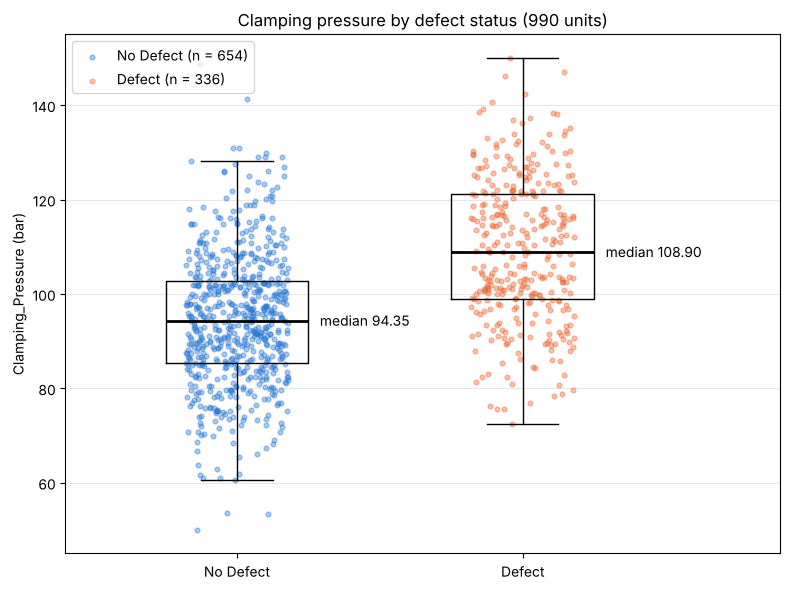

In [6]:
group_order = ["No Defect", "Defect"]
group_data = [no_defect_pressure, defect_pressure]
group_colours = {"No Defect": "#2a78d6", "Defect": "#eb6834"}

fig, ax = plt.subplots(figsize=(8, 6))

rng = np.random.default_rng(42)
for position, (name, values) in enumerate(zip(group_order, group_data), start=1):
    x_positions = position + rng.uniform(-0.18, 0.18, size=len(values))
    ax.scatter(x_positions, values, s=12, alpha=0.4, color=group_colours[name],
               label=f"{name} (n = {len(values)})", zorder=2)

ax.boxplot(group_data, widths=0.5, showfliers=False, zorder=3,
           medianprops={"color": "black", "linewidth": 2})

for position, values in enumerate(group_data, start=1):
    ax.text(position + 0.29, values.median(), f"median {values.median():.2f}", va="center")

ax.set_xticks([1, 2], group_order)
ax.set_xlim(0.4, 2.9)
ax.set_ylabel("Clamping_Pressure (bar)")
ax.set_title("Clamping pressure by defect status (990 units)")
ax.grid(axis="y", alpha=0.3)
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

**Step 2.3 – Supporting chart: overlaid histograms.**
Purpose: show the shape of each group's distribution. `density=True` scales each histogram to the same total area, so the two groups can be compared fairly even though there are 654 No Defect units and only 336 Defect units.

- The bins are 5 bar wide, from 50 to 150 bar.
- The dashed vertical lines mark each group's median.

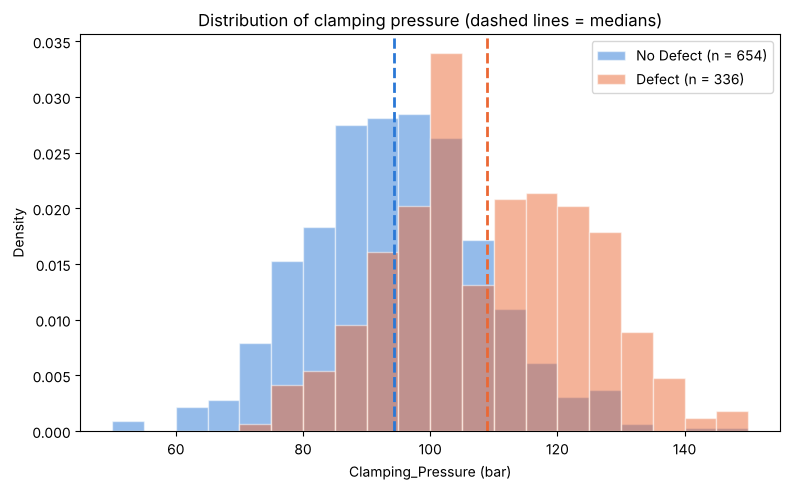

In [7]:
bin_edges = np.arange(50, 155, 5)

fig, ax = plt.subplots(figsize=(8, 5))
for name, values in zip(group_order, group_data):
    ax.hist(values, bins=bin_edges, density=True, alpha=0.5,
            color=group_colours[name], edgecolor="white", label=f"{name} (n = {len(values)})")
    ax.axvline(values.median(), color=group_colours[name], linestyle="--", linewidth=2)

ax.set_xlabel("Clamping_Pressure (bar)")
ax.set_ylabel("Density")
ax.set_title("Distribution of clamping pressure (dashed lines = medians)")
ax.legend()
plt.tight_layout()
plt.show()

**Step 2.4 – Supporting chart: defect rate by pressure band.**
Purpose: turn the comparison into the question the plant cares about – out of all units run in a given pressure range, what percentage were defective?

- Five bands: below 90, 90–99.9, 100–109.9, 110–119.9, and 120 bar and above. `right=False` means each band includes its lower edge, so 90–99.9 means 90 ≤ pressure < 100.
- Defect rate = defects ÷ units × 100%. The grey dashed line on the chart is the overall defect rate.
- The code also prints the defect rate between 85 and 100 bar (both ends included), which is used for the trial proposal in Section 4.

               units  defects  defect_rate_%
Pressure_Band                               
below 90         278       33           11.9
90-99.9          246       61           24.8
100-109.9        221       79           35.7
110-119.9        127       71           55.9
120 and above    118       92           78.0

Overall defect rate: 336 / 990 = 33.9%
Highest band vs lowest band: 78.0% / 11.9% = 6.6 times
85 to 100 bar: 79 defects out of 356 units = 22.2%


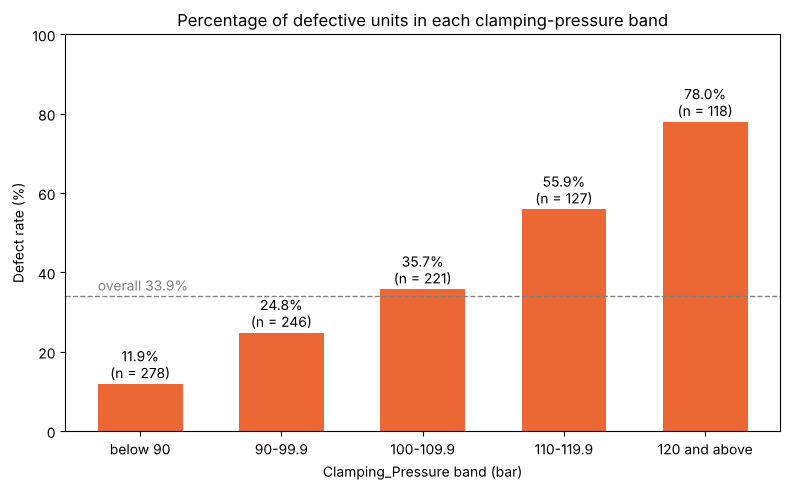

In [8]:
band_edges = [0, 90, 100, 110, 120, np.inf]
band_labels = ["below 90", "90-99.9", "100-109.9", "110-119.9", "120 and above"]

clean_data["Pressure_Band"] = pd.cut(clean_data["Clamping_Pressure"], bins=band_edges,
                                     labels=band_labels, right=False)

band_table = clean_data.groupby("Pressure_Band", observed=True)["defect"].agg(units="count", defects="sum")
band_table["defect_rate_%"] = 100 * band_table["defects"] / band_table["units"]
print(band_table.round(1))
print()

overall_rate = 100 * clean_data["defect"].mean()
print(f"Overall defect rate: {clean_data['defect'].sum()} / {len(clean_data)} = {overall_rate:.1f}%")
highest_rate = band_table["defect_rate_%"].iloc[-1]
lowest_rate = band_table["defect_rate_%"].iloc[0]
print(f"Highest band vs lowest band: {highest_rate:.1f}% / {lowest_rate:.1f}% = {highest_rate / lowest_rate:.1f} times")

in_85_to_100 = clean_data["Clamping_Pressure"].between(85, 100)
rate_85_to_100 = 100 * clean_data.loc[in_85_to_100, "defect"].mean()
print(f"85 to 100 bar: {clean_data.loc[in_85_to_100, 'defect'].sum()} defects out of {in_85_to_100.sum()} units = {rate_85_to_100:.1f}%")

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(band_labels, band_table["defect_rate_%"], color=group_colours["Defect"], width=0.6)
for bar, rate, units in zip(bars, band_table["defect_rate_%"], band_table["units"]):
    ax.text(bar.get_x() + bar.get_width() / 2, rate + 1.5, f"{rate:.1f}%\n(n = {units})", ha="center")
ax.axhline(overall_rate, color="grey", linestyle="--", linewidth=1)
ax.text(-0.3, overall_rate + 1.5, f"overall {overall_rate:.1f}%", color="grey")

ax.set_ylim(0, 100)
ax.set_xlabel("Clamping_Pressure band (bar)")
ax.set_ylabel("Defect rate (%)")
ax.set_title("Percentage of defective units in each clamping-pressure band")
plt.tight_layout()
plt.show()

**Variable chosen:** I chose **Clamping_Pressure (bar)**.

**Chart type used:** I used a **box plot** of Clamping_Pressure for the Defect and No Defect groups, with every unit drawn as a jittered dot on top of the box. I also used two supporting charts: **overlaid density histograms** of the two groups, and a **bar chart of the defect rate in five pressure bands**.

**Why you chose this chart type:**

- I am comparing one numerical variable across two categories. A box plot shows the median, the middle 50% (Q1 to Q3) and the spread of both groups side by side, so the difference in centre and spread is visible at a glance.
- A box plot is based on medians and quartiles, so it is not distorted by the 9 outliers I kept. This also matches the rank-based Mann-Whitney U test I use in Section 3.
- A box on its own hides how many units are in each group and how much the groups overlap. The jittered dots show both (654 vs 336 units, and a large overlap).
- The density histograms show the shape of each distribution (roughly symmetric or not), which supports the normality checks in Section 3. I used density rather than counts because the groups are different sizes.
- The defect-rate bar chart shows the practical question: how likely is a defect at a given pressure setting.

**Pattern observed and descriptive statistics:**

| Clamping_Pressure (bar) | Defect (n = 336) | No Defect (n = 654) |
|---|---|---|
| Mean | 109.24 | 94.54 |
| Standard deviation | 15.15 | 13.85 |
| Minimum | 72.50 | 50.00 |
| Q1 | 98.88 | 85.32 |
| Median | 108.90 | 94.35 |
| Q3 | 121.12 | 102.78 |
| Maximum | 150.00 | 148.80 |
| IQR | 22.25 | 17.45 |
| Skewness | 0.052 | 0.166 |

- **Defect units ran at higher clamping pressure.** The median is 108.90 bar for Defect and 94.35 bar for No Defect, a difference of 108.90 − 94.35 = 14.55 bar. The means differ by 109.24 − 94.54 = 14.70 bar.
- **The Defect group is more spread out:** IQR 22.25 vs 17.45 bar, standard deviation 15.15 vs 13.85 bar.
- **Both groups are roughly symmetric** (skewness 0.052 and 0.166, both close to 0). The No Defect histogram is roughly bell-shaped. The Defect histogram is shifted to the right and is flatter and less even (a peak at 100–105 bar and a broad shoulder from about 110 to 125 bar), which fits the Shapiro-Wilk result in Section 3.
- **The groups overlap heavily.** The middle 50% of Defect units (98.88–121.12 bar) overlaps the middle 50% of No Defect units (85.32–102.78 bar), many No Defect units sit above 110 bar, and some Defect units sit below 90 bar. Pressure alone cannot tell a defective unit from a good one.
- **The defect rate rises steadily with pressure:** below 90 bar 11.9% (33 of 278), 90–99.9 bar 24.8% (61 of 246), 100–109.9 bar 35.7% (79 of 221), 110–119.9 bar 55.9% (71 of 127), 120 bar and above 78.0% (92 of 118). The highest band has about 6.6 times the defect rate of the lowest band (overall rate 33.9%).

## SECTION 3: STATISTICAL ANALYSIS

Run your assumption checks (normality and variance homogeneity) and your statistical test in the code cell below. Then, in the answer cell that follows, state your test explicitly, justify your test choice, and interpret your result.

**Step 3.1 – Assumption checks.**
Purpose: Shapiro-Wilk tests whether each group could come from a normal distribution (H0: normal). Levene's test checks whether the two groups have equal variances (H0: equal variances). Both use α = 0.05. These results decide which test to use.

- Shapiro-Wilk is run on each group separately.
- SciPy's Levene test is centred on the median by default, which makes it less sensitive to non-normal data.

In [9]:
alpha = 0.05

shapiro_defect = stats.shapiro(defect_pressure)
shapiro_no_defect = stats.shapiro(no_defect_pressure)
print("Normality (Shapiro-Wilk):")
for name, result in [("Defect", shapiro_defect), ("No Defect", shapiro_no_defect)]:
    if result.pvalue < alpha:
        decision = "p < 0.05 -> reject normality"
    else:
        decision = "p >= 0.05 -> no evidence against normality"
    print(f"  {name:<10} W = {result.statistic:.4f}, p = {result.pvalue:.4f}  ({decision})")
print()

levene_result = stats.levene(defect_pressure, no_defect_pressure)
if levene_result.pvalue < alpha:
    decision = "p < 0.05 -> variances are not equal"
else:
    decision = "p >= 0.05 -> no evidence of unequal variances"
print("Equal variances (Levene):")
print(f"  W = {levene_result.statistic:.2f}, p = {levene_result.pvalue:.4f}  ({decision})")
print(f"  Standard deviations: Defect = {defect_pressure.std():.2f}, No Defect = {no_defect_pressure.std():.2f} bar")

Normality (Shapiro-Wilk):
  Defect     W = 0.9913, p = 0.0451  (p < 0.05 -> reject normality)
  No Defect  W = 0.9965, p = 0.1672  (p >= 0.05 -> no evidence against normality)

Equal variances (Levene):
  W = 10.06, p = 0.0016  (p < 0.05 -> variances are not equal)
  Standard deviations: Defect = 15.15, No Defect = 13.85 bar


**Step 3.2 – Main test: Mann-Whitney U, with effect sizes.**
Purpose: test whether Clamping_Pressure tends to be higher in one group than the other, without assuming normality. The p-value says whether the difference is likely to be chance. The effect sizes say how big the difference is:
- *Probability of superiority* = U ÷ (n₁ × n₂): the chance that a randomly chosen Defect unit has a higher pressure than a randomly chosen No Defect unit (0.5 = no difference).
- *Rank-biserial correlation* = 2 × probability of superiority − 1 (0 = no difference, 1 = complete separation).

In [10]:
mw_result = stats.mannwhitneyu(defect_pressure, no_defect_pressure, alternative="two-sided")
n_defect = len(defect_pressure)
n_no_defect = len(no_defect_pressure)

print(f"Mann-Whitney U = {mw_result.statistic:,.1f}")
print(f"p-value = {mw_result.pvalue:.3g}")
if mw_result.pvalue < alpha:
    print("p < 0.05 -> reject H0")
else:
    print("p >= 0.05 -> do not reject H0")
print()

prob_superiority = mw_result.statistic / (n_defect * n_no_defect)
print(f"Probability of superiority = {mw_result.statistic:,.1f} / ({n_defect} x {n_no_defect}) "
      f"= {mw_result.statistic:,.1f} / {n_defect * n_no_defect:,} = {prob_superiority:.3f}")

rank_biserial = 2 * prob_superiority - 1
print(f"Rank-biserial correlation = 2 x {prob_superiority:.3f} - 1 = {rank_biserial:.3f}")

Mann-Whitney U = 167,195.5
p-value = 2.83e-41
p < 0.05 -> reject H0

Probability of superiority = 167,195.5 / (336 x 654) = 167,195.5 / 219,744 = 0.761
Rank-biserial correlation = 2 x 0.761 - 1 = 0.522


**Step 3.3 – Size of the pressure gap: Hodges-Lehmann shift with a 95% confidence interval.**
Purpose: estimate how many bar higher Defect units typically are. Every Defect unit is paired with every No Defect unit (336 × 654 = 219,744 pairs), the pressure difference is worked out for each pair, and the median of all these differences is the Hodges-Lehmann shift. The 95% confidence interval uses the large-sample method linked to the Mann-Whitney test: sort the differences and cut off *k* of them from each end.

- `np.subtract.outer` builds the table of all (Defect − No Defect) differences; `.ravel()` flattens it into one long list, which is then sorted.
- k = (n₁ × n₂ ÷ 2) − 1.96 × √(n₁ × n₂ × (n₁ + n₂ + 1) ÷ 12), rounded down. The first part is the mean of U and the square root is the standard deviation of U.

In [11]:
pair_differences = np.subtract.outer(defect_pressure.to_numpy(), no_defect_pressure.to_numpy()).ravel()
pair_differences = np.sort(pair_differences)
total_pairs = len(pair_differences)

hl_shift = np.median(pair_differences)

u_mean = total_pairs / 2
u_sd = np.sqrt(n_defect * n_no_defect * (n_defect + n_no_defect + 1) / 12)
k = int(np.floor(u_mean - 1.96 * u_sd))
hl_ci_lower = pair_differences[k]
hl_ci_upper = pair_differences[total_pairs - k - 1]

print(f"Pairs compared: {total_pairs:,}")
print(f"Hodges-Lehmann shift (Defect - No Defect) = {hl_shift:.2f} bar")
print(f"k = {u_mean:,.0f} - 1.96 x {u_sd:,.1f} = {k:,} differences cut from each end")
print(f"95% confidence interval: {hl_ci_lower:.2f} to {hl_ci_upper:.2f} bar")

Pairs compared: 219,744
Hodges-Lehmann shift (Defect - No Defect) = 14.70 bar
k = 109,872 - 1.96 x 4,260.0 = 101,522 differences cut from each end
95% confidence interval: 12.70 to 16.70 bar


**Step 3.4 – Sensitivity check: Welch's t-test.**
Purpose: check that the conclusion does not depend on the choice of test. Welch's t-test compares means and does not assume equal variances. With 336 and 654 units, the sample means are close to normally distributed even if the raw data are slightly non-normal (Central Limit Theorem), so it is a reasonable cross-check.

- Standard error of the difference: SE = √(s₁²/n₁ + s₂²/n₂).
- Welch–Satterthwaite degrees of freedom: df = (s₁²/n₁ + s₂²/n₂)² ÷ [ (s₁²/n₁)² ÷ (n₁ − 1) + (s₂²/n₂)² ÷ (n₂ − 1) ].
- 95% confidence interval for the mean difference = mean difference ± t(0.975, df) × SE.

In [12]:
welch_result = stats.ttest_ind(defect_pressure, no_defect_pressure, equal_var=False)
mean_difference = defect_pressure.mean() - no_defect_pressure.mean()

var_part_defect = defect_pressure.var() / n_defect
var_part_no_defect = no_defect_pressure.var() / n_no_defect
standard_error = np.sqrt(var_part_defect + var_part_no_defect)

welch_df = (var_part_defect + var_part_no_defect) ** 2 / (
    var_part_defect ** 2 / (n_defect - 1) + var_part_no_defect ** 2 / (n_no_defect - 1))
t_critical = stats.t.ppf(0.975, welch_df)

ci_lower = mean_difference - t_critical * standard_error
ci_upper = mean_difference + t_critical * standard_error

print(f"Welch's t = {welch_result.statistic:.2f}, df = {welch_df:.1f}, p-value = {welch_result.pvalue:.3g}")
print(f"Mean difference = {mean_difference:.2f} bar, standard error = {standard_error:.3f} bar")
print(f"95% CI = {mean_difference:.2f} +/- {t_critical:.3f} x {standard_error:.3f} = {ci_lower:.2f} to {ci_upper:.2f} bar")

Welch's t = 14.87, df = 625.3, p-value = 4.78e-43
Mean difference = 14.70 bar, standard error = 0.988 bar
95% CI = 14.70 +/- 1.964 x 0.988 = 12.76 to 16.64 bar


**Step 3.5 – Supporting check (used in Section 4): is Clamping_Pressure linked to other parameters?**
Purpose: if Clamping_Pressure moves together with other process parameters, a difference between the groups could be caused partly by those parameters instead. This shows the six strongest correlations (Pearson r).

- The correlations are sorted by strength (the size of r, ignoring the plus or minus sign).

In [13]:
pressure_correlations = clean_data[parameter_columns].corr()["Clamping_Pressure"].drop("Clamping_Pressure")

order_by_strength = pressure_correlations.abs().sort_values(ascending=False).index
print("Strongest correlations with Clamping_Pressure:")
print(pressure_correlations[order_by_strength].head(6).round(2))

Strongest correlations with Clamping_Pressure:
Tool_Wear             -0.76
Machine_Load           0.63
Material_Thickness    -0.55
Power_Consumption      0.53
Vibration_Amplitude    0.45
Tool_Angle            -0.45
Name: Clamping_Pressure, dtype: float64


**Null and alternative hypothesis (H0 and H1):**

- **H0:** The distribution of Clamping_Pressure is the same for Defect and No Defect units (a randomly chosen Defect unit is equally likely to have a higher or a lower pressure than a randomly chosen No Defect unit).
- **H1:** The distributions differ (one group tends to have higher Clamping_Pressure than the other).
- Two-sided test, significance level α = 0.05.

**Assumption check results (normality and variance homogeneity):**

- **Normality (Shapiro-Wilk):** Defect W = 0.9913, **p = 0.0451** (below 0.05, so normality is rejected). No Defect W = 0.9965, **p = 0.1672** (above 0.05, so no evidence against normality).
- **Equal variances (Levene's test, median-centred):** W = 10.06, **p = 0.0016** (below 0.05, so the variances are not equal; standard deviations 15.15 vs 13.85 bar).

**Statistical test used:** I used the **Mann-Whitney U test** (two-sided).

**Why you chose this test:**

- I am comparing one numerical variable between two independent groups (each unit is in only one group), so I need a two-sample test.
- The independent-samples t-test assumes both groups are normally distributed. The Defect group failed the Shapiro-Wilk test (p = 0.0451), so this assumption is not met for both groups. The Mann-Whitney U test works on ranks and does not need normality.
- Because it uses ranks, it is also not dominated by the 9 outliers I kept in Section 1.
- Levene's test showed unequal variances. Because the spreads differ, I interpret the Mann-Whitney result as "Defect units tend to have higher pressure" rather than strictly "the medians differ", and I back this up with the probability of superiority.
- The Defect p-value (0.0451) is only just below 0.05, and with 336 values Shapiro-Wilk can flag small departures from normality. For this reason I also ran Welch's t-test, which does not assume equal variances, as a sensitivity check.

**Test result and interpretation:**

- **Mann-Whitney U = 167,195.5, p = 2.83 × 10⁻⁴¹.** Since p < 0.05, I reject H0. There is very strong evidence that Clamping_Pressure differs between the groups, with Defect units tending to run at higher pressure.
- **Effect size:** probability of superiority = 167,195.5 ÷ (336 × 654) = 167,195.5 ÷ 219,744 = **0.761**. If one Defect unit and one No Defect unit are picked at random, the Defect unit has the higher clamping pressure 76.1% of the time (50% would mean no difference). Rank-biserial correlation = 2 × 0.761 − 1 = **0.522**. This is a substantial difference, but not complete separation, which matches the overlap seen in Section 2.
- **Size of the gap:** Hodges-Lehmann shift = **14.70 bar**, 95% confidence interval **12.70 to 16.70 bar**. Defect units typically ran about 15 bar higher.
- **Sensitivity check:** Welch's t = 14.87, df = 625.3, p = 4.78 × 10⁻⁴³. Mean difference = 14.70 bar, 95% CI 12.76 to 16.64 bar. Both tests reach the same conclusion and give almost the same size of gap, so the result does not depend on the choice of test.
- **Interpretation:** The pressure difference between Defect and No Defect units is real and not due to chance. However, this is an association, not proof of cause. Step 3.5 shows Clamping_Pressure is correlated with Tool_Wear (r = −0.76), Machine_Load (r = 0.63), Material_Thickness (r = −0.55) and Power_Consumption (r = 0.53), so these may also play a part (discussed in Section 4).

## SECTION 4: ENGINEERING IMPLICATIONS

What do your visual and statistical findings jointly imply? What is your proposed course of action? What are the limits of your evidence (e.g. sample size, what your data can and cannot rule out)?

**Your answer:**

**What the findings jointly imply**

The visual and statistical results point the same way. In the charts, Defect units sit higher (median 108.90 vs 94.35 bar) and the defect rate climbs steadily from 11.9% below 90 bar to 78.0% at 120 bar and above. The Mann-Whitney U test shows this difference is very unlikely to be chance (p = 2.83 × 10⁻⁴¹), and the typical gap is about 14.7 bar (95% CI 12.7 to 16.7 bar). Welch's t-test gives the same answer. So **high clamping pressure is strongly associated with defects in this dataset**.

However, the probability of superiority is 0.761, not 1.0. The groups overlap heavily, and 11.9% of units below 90 bar were still defective. Clamping pressure is therefore one warning sign, not the whole explanation, and it cannot predict on its own whether a particular unit will be defective.

A possible engineering mechanism is over-clamping: too much clamping force can deform the workpiece, which springs back after unclamping and is left out of tolerance. This is a hypothesis to test, not something this data proves.

**Proposed course of action**

1. **Run a controlled trial.** Alternate batches between a reduced setting of 85–100 bar and the current settings, keeping everything else fixed (same machine, material batch, tool condition and operator). I chose 85–100 bar because the middle half of No Defect units ran between 85.32 and 102.78 bar, and the defect rate in this range in the data is 22.2% (79 of 356) compared with 33.9% overall.
2. **Check that parts are still held firmly at the lower setting**, by monitoring Vibration_Amplitude and Alignment_Error during the trial. Under-clamping can let the part move or chatter, which would create a different kind of defect.
3. **Run about 230 units per setting**, which gives roughly an 80% chance of detecting a drop in defect rate from 33.9% to about 22% at α = 0.05. (Sample size per group n = (1.96 × √(2 × 0.2805 × 0.7195) + 0.84 × √(0.339 × 0.661 + 0.222 × 0.778))² ÷ (0.339 − 0.222)² = (1.245 + 0.529)² ÷ 0.01369 ≈ 230, where 0.2805 is the average of the two rates.) Compare the two defect rates with a two-proportion test, and track the defect rate on a p-chart (control chart) so any change over time is visible.

**Limits of the evidence**

- **Association, not causation.** The data is observational. Clamping_Pressure moves together with Tool_Wear (r = −0.76), Machine_Load (r = 0.63), Material_Thickness (r = −0.55) and Power_Consumption (r = 0.53), so any of these could be part of the cause. Only a controlled trial can separate them.
- **Heavy overlap between groups**, so a pressure limit alone will not remove all defects.
- **No defect type is recorded.** I cannot tell whether high-pressure defects are distortion, clamp marks or something else, which limits the root-cause analysis.
- **Limited range.** No readings exist below 50 bar or above 150 bar, and very few are near the bottom of the range (the three lowest, 50.0–53.6 bar, are outliers), so the data says little about very low pressures, where part movement could become a problem.
- **Sample size.** 990 units is large enough to detect the overall difference, but the band estimates are less precise (for example, only 118 units at 120 bar and above). The normality result for the Defect group was borderline (p = 0.0451), although both tests agree.
- **Unknown context.** The data does not say which machines, time period or material batches it covers, so the result may not carry over to other conditions.

## SECTION 5A: STAKEHOLDER SUMMARY — VISUAL FINDINGS

Write a short, jargon-free summary of your visual findings and their implication, for the plant manager (non-technical, no statistics background).

**Your answer:**

We looked at the clamping pressure used for 990 parts: 336 came out defective and 654 came out good.

- **Defective parts were usually clamped harder.** A typical defective part was clamped at about 109 bar, while a typical good part was clamped at about 94 bar – roughly 15 bar higher.
- **The harder the clamping, the more defects.** Below 90 bar, about 1 in 8 parts was defective. At 120 bar and above, nearly 4 in 5 parts were defective.
- **But it is not the whole story.** Many good parts were also made at high pressure, and some defective parts were made at low pressure, so clamping pressure is one warning sign rather than the only cause.

**What this means:** clamping pressure is worth acting on. The sensible next step is a short, controlled trial at a lower clamping setting to see whether defects actually go down.

## SECTION 5B: STAKEHOLDER SUMMARY — STATISTICAL FINDINGS

Write a short, jargon-free summary of your statistical findings and their implication, for the same reader.

**Your answer:**

We checked whether the pressure difference between defective and good parts could just be luck in this particular set of parts.

- **It is not luck.** If clamping pressure made no difference at all, the chance of seeing a gap this large is practically zero – far less than one in a trillion.
- **How big is the effect?** If you pick one defective part and one good part at random, the defective part was clamped harder about 3 times out of 4.
- **How big is the gap?** We are 95% confident that defective parts were typically clamped between about 13 and 17 bar harder than good parts.
- **Two different checking methods gave the same answer**, so the result is reliable.

**What it does not tell us:** it does not prove that high pressure *causes* defects. Parts clamped harder also tended to differ in other ways, such as tool wear, machine load and material thickness, and any of these could be involved.

**Recommendation:** run a controlled trial. Alternate batches at a lower setting (85–100 bar) with batches at the current settings, keep everything else the same, run about 230 parts of each, and compare the defect rates. First confirm that parts are still held firmly at the lower setting.

## SECTION 6: PROCESS REFLECTION

These answers should be honest, specific, and refer to your own actual results and decisions. **300-word limit for your combined response.** You may be asked about this material in the viva.

**1. Describe a real problem you encountered.** Explain what you expected to happen and what happened instead. Be specific and avoid vague statements such as simply saying you were confused.

**2. Explain your first response.** Describe the first thing you did to try to resolve the issue and why you chose to do that. This could include things like checking your data, revisiting your analysis choice, or examining the output more closely.

**3. Describe what you learnt and how you applied it.** Explain one clear thing you learnt about data analysis, how you learnt it, and how that learning helped you change or improve your analysis.

**4. End with a clear insight.** End your reflection with a short insight about how this experience improved your understanding of data analysis. This insight should be connected to what actually happened in this task.

**Your answer:**

*(replace this line with your answer — respond to all four points above in a single combined response)*

## APPENDIX A: AI USAGE LOG

Submit your complete, unedited AI chat log as a **separate file** alongside this notebook (not pasted into a cell here). Name it `AI_Usage_Log` with an appropriate extension (e.g. `.txt`, `.pdf`, or exported chat history). Do not summarise or clean it up — submit the full conversation history for any AI tool you used on this project.

**Confirm here that you have attached this file separately:** *(yes / no)*
